In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import expon, reciprocal


from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.inspection import PartialDependenceDisplay


from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import numpy as np
from scipy.stats import randint, uniform, loguniform
import joblib
import xgboost as xgb

In [2]:
pem = pd.read_csv('../data/pem_electrolyser_dataset.csv', encoding='ISO-8859-1')

In [3]:
pem.head()

,electrolysis_type,Anode_type,Cathode_type,Anode_GDE,Cathode_GDE,electrode_area(cm2),cathode_flow_area(cm2),anode_flow_area(cm2),membrane_type,cathode_catalyst,...,Cell_current_des(A/cm2),power(w),power(W/cm2),water_flow_rate(ml/min),Hydrogen_flow_rate,Temprature_cell(k),Pressuer(atm),Electrode_shape,Flow_type_A (Number),Flow_type_C (Number)
0,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.006964,0.110002,0.018804,6,0.100,293.15,1.0,rectangular,1,1
1,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.014786,0.259501,0.044359,6,0.675,293.15,1.0,rectangular,1,1
2,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.026414,0.509915,0.087165,6,1.100,293.15,1.0,rectangular,1,1
3,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.043238,0.910592,0.155657,6,1.900,293.15,1.0,rectangular,1,1
4,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.064428,1.469932,0.251270,6,3.000,293.15,1.0,rectangular,1,1


In [4]:
# rename columns and set all to lowercase for consistency
pem.columns = pem.columns.str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

In [5]:
# remove duplicate rows if there are any
pem.drop_duplicates(inplace=True)

In [6]:
pem.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1042 entries, 0 to 1061
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   electrolysis_type      1042 non-null   object 
 1   anode_type             1042 non-null   object 
 2   cathode_type           1042 non-null   object 
 3   anode_gde              1042 non-null   object 
 4   cathode_gde            1042 non-null   object 
 5   electrode_areacm2      1042 non-null   float64
 6   cathode_flow_areacm2   1042 non-null   float64
 7   anode_flow_areacm2     1042 non-null   float64
 8   membrane_type          1042 non-null   object 
 9   cathode_catalyst       1042 non-null   object 
 10  anode_catalyst         1042 non-null   object 
 11  catholyte              1042 non-null   object 
 12  anolyte                1042 non-null   object 
 13  cell_design_type       1042 non-null   object 
 14  cell_design_number     1042 non-null   int64  
 15  cell_volt

In [7]:
# Number of occurences of items in each column
for col in pem.columns:
    col = str(col)
    print(col + ': ', '\n', pem[col].value_counts(), '\n')

electrolysis_type:  
 electrolysis_type
PEM    1042
Name: count, dtype: int64 

anode_type:  
 anode_type
Titanium                                                            519
carbon_plate                                                        334
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Ni_foam                                                               6
Name: count, dtype: int64 

cathode_type:  
 cathode_type
carbon_plate                                                        508
Titanium                                                            351
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Name: count, dtype: int64 

anode_gde:  
 an

In [8]:
print(pem.describe()) # describe dataset

       electrode_areacm2  cathode_flow_areacm2  anode_flow_areacm2  \
count        1042.000000           1042.000000         1042.000000   
mean           39.664875             18.225058           18.688321   
std            30.695271             16.026585           15.699181   
min             9.000000              4.000000            4.000000   
25%            16.000000              5.720000            6.150000   
50%            25.000000              7.920000            9.000000   
75%            64.000000             25.000000           25.000000   
max           100.000000             50.000000           50.000000   

       cell_design_number  cell_voltage  cell_current_desa/cm2       powerw  \
count         1042.000000   1042.000000            1042.000000  1042.000000   
mean             1.970250      3.596026               0.485973    64.177850   
std              2.486868      4.193654               0.483831   153.517598   
min              1.000000      1.380000              

In [9]:
for col in pem.select_dtypes(include='object').columns: #assign category type to categorical features
    pem[col] = pem[col].astype('category')
    
#remove cell_design_type
pem.drop('cell_design_type', axis=1, inplace=True)
pem.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1042 entries, 0 to 1061
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   electrolysis_type      1042 non-null   category
 1   anode_type             1042 non-null   category
 2   cathode_type           1042 non-null   category
 3   anode_gde              1042 non-null   category
 4   cathode_gde            1042 non-null   category
 5   electrode_areacm2      1042 non-null   float64 
 6   cathode_flow_areacm2   1042 non-null   float64 
 7   anode_flow_areacm2     1042 non-null   float64 
 8   membrane_type          1042 non-null   category
 9   cathode_catalyst       1042 non-null   category
 10  anode_catalyst         1042 non-null   category
 11  catholyte              1042 non-null   category
 12  anolyte                1042 non-null   category
 13  cell_design_number     1042 non-null   int64   
 14  cell_voltage           1042 non-null   float6

In [10]:
# Change flow_type to categorical as well
pem['flow_type_a_number'] = pem['flow_type_a_number'].astype('category')
pem['flow_type_c_number'] = pem['flow_type_c_number'].astype('category')

In [11]:
for columns in pem.columns:
    if pem[columns].dtype == 'category':
        print(f"Value counts for {columns}:\n{pem[columns].value_counts()}\n")

Value counts for electrolysis_type:
electrolysis_type
PEM    1042
Name: count, dtype: int64

Value counts for anode_type:
anode_type
Titanium                                                            519
carbon_plate                                                        334
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Ni_foam                                                               6
Name: count, dtype: int64

Value counts for cathode_type:
cathode_type
carbon_plate                                                        508
Titanium                                                            351
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Name

In [12]:
for col in pem.columns:
    if pem[col].dtypes in ['int64', 'float64']:
        min_value = pem[col].min()
        max_value = pem[col].max()
        print(f"Min, max for {col}:\n min = {min_value}:\n max = {max_value}")
    

Min, max for electrode_areacm2:
 min = 9.0:
 max = 100.0
Min, max for cathode_flow_areacm2:
 min = 4.0:
 max = 50.0
Min, max for anode_flow_areacm2:
 min = 4.0:
 max = 50.0
Min, max for cell_design_number:
 min = 1:
 max = 10
Min, max for cell_voltage:
 min = 1.38:
 max = 19.0
Min, max for cell_current_desa/cm2:
 min = 0.00024083:
 max = 2.0
Min, max for powerw:
 min = 0.00222166:
 max = 1280.0
Min, max for powerw/cm2:
 min = 0.000361245:
 max = 25.6
Min, max for water_flow_rateml/min:
 min = 1:
 max = 1000
Min, max for hydrogen_flow_rate:
 min = 0.0:
 max = 5000.0
Min, max for temprature_cellk:
 min = 293.15:
 max = 403.15
Min, max for pressueratm:
 min = 1.0:
 max = 3.0


#### Plot histogram and boxplots of numerical data

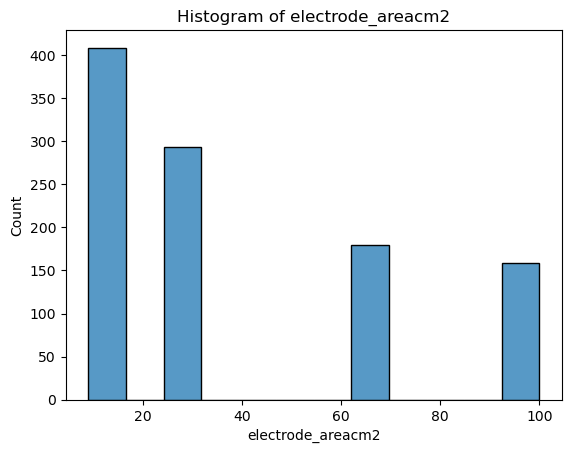

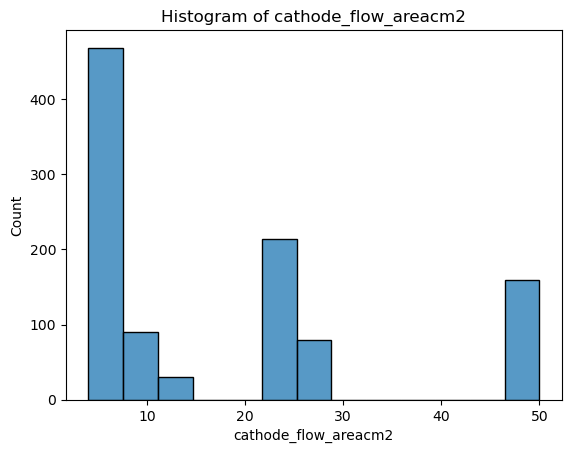

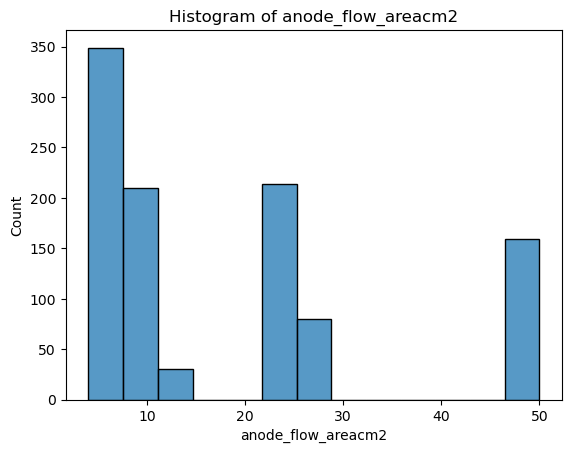

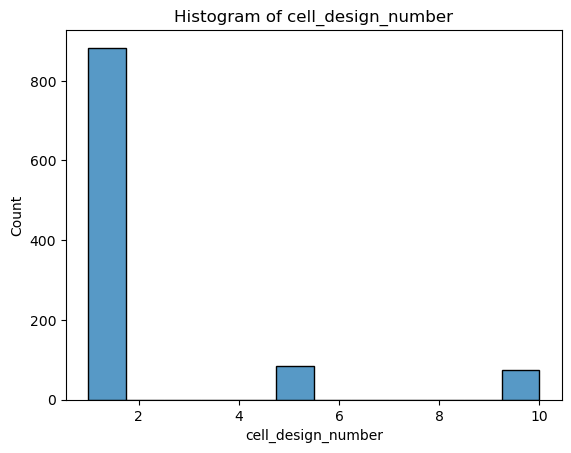

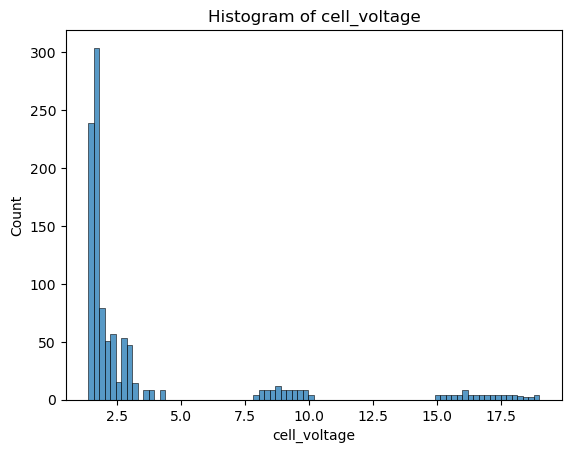

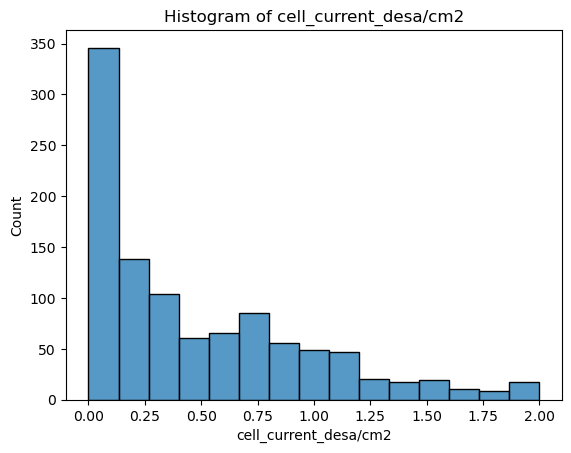

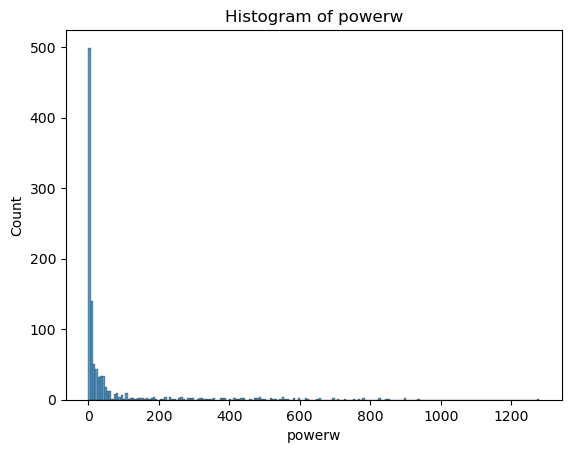

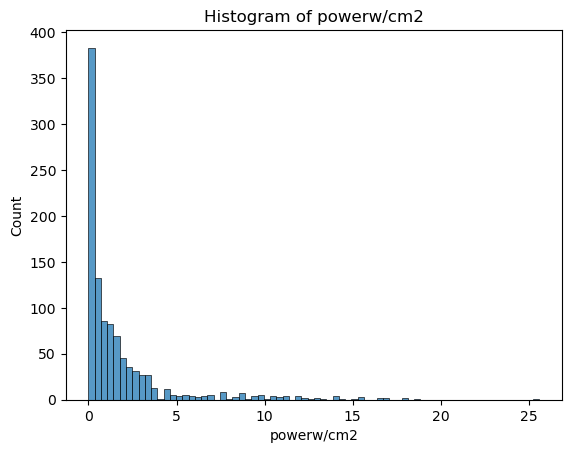

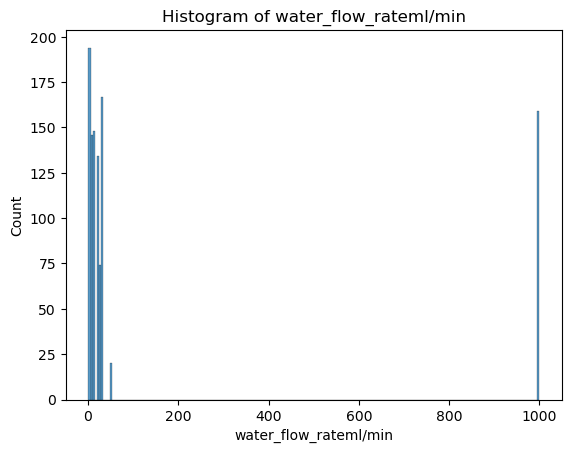

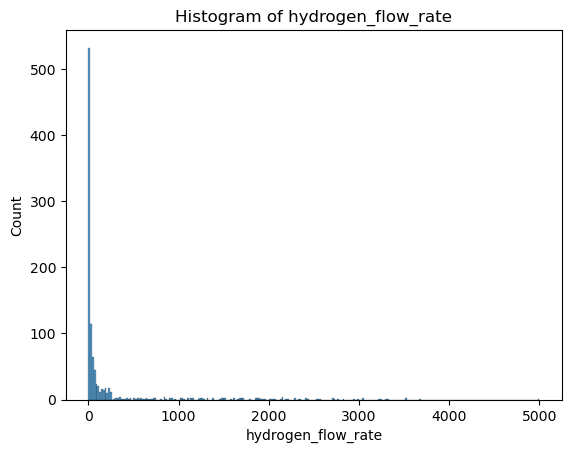

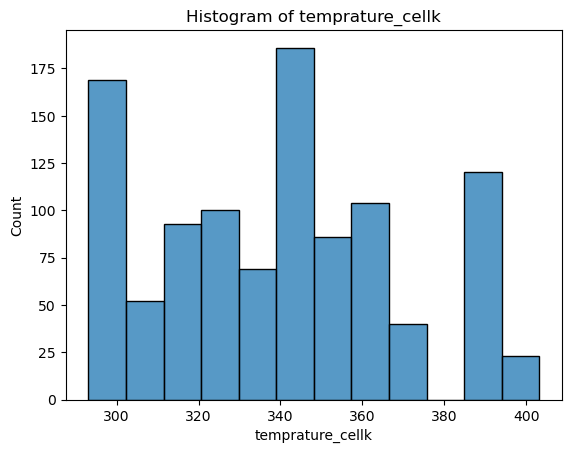

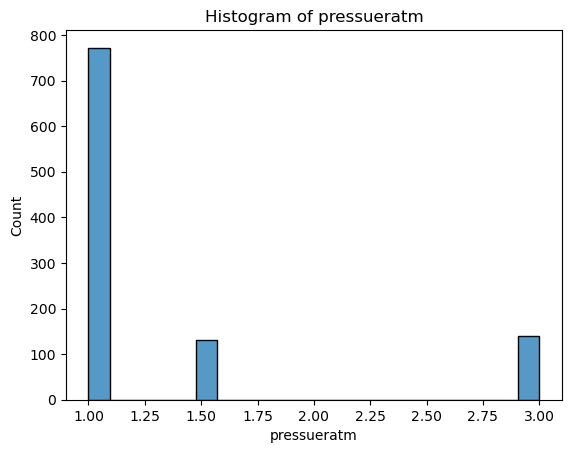

In [13]:
for col in pem.select_dtypes(include=['float64', 'int64']).columns:
    col = str(col)
    sns.histplot(pem[col])
    plt.title('Histogram of ' + col)
    plt.show()

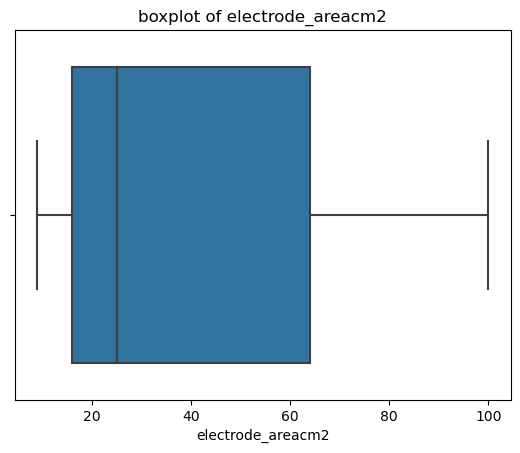

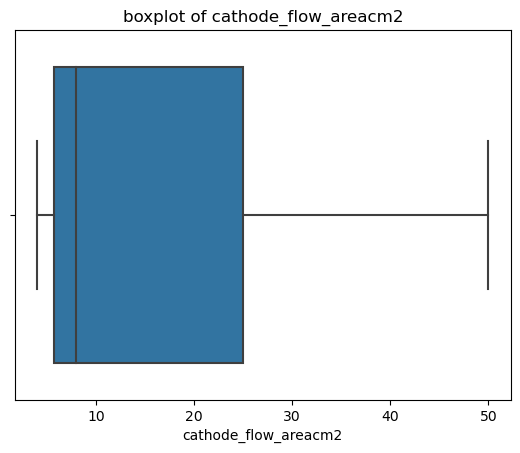

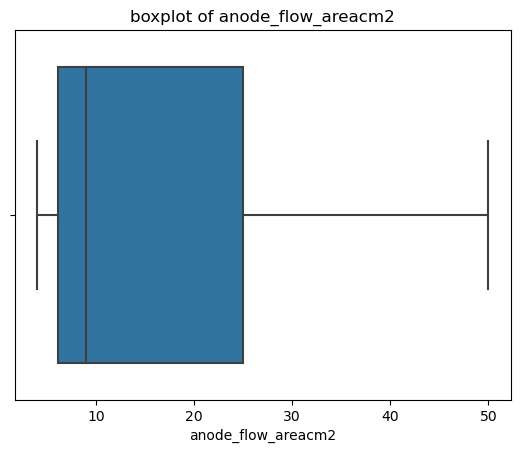

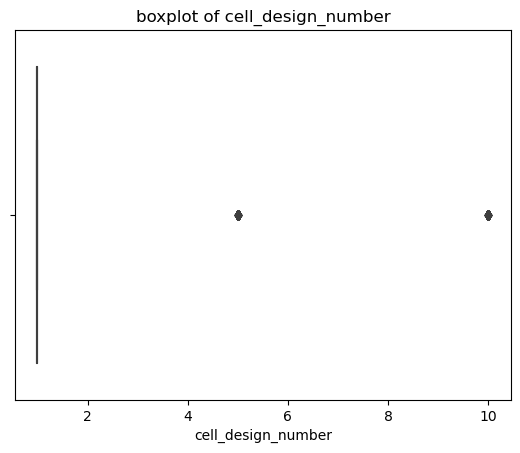

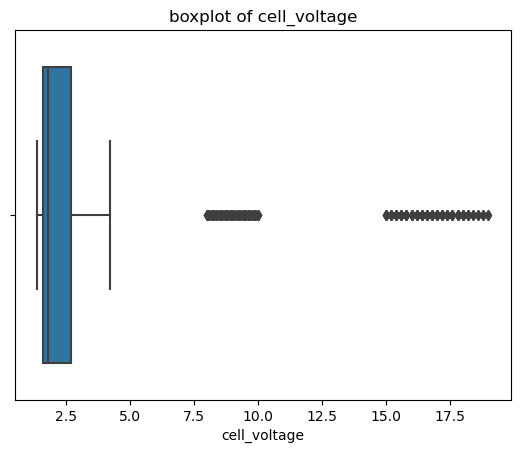

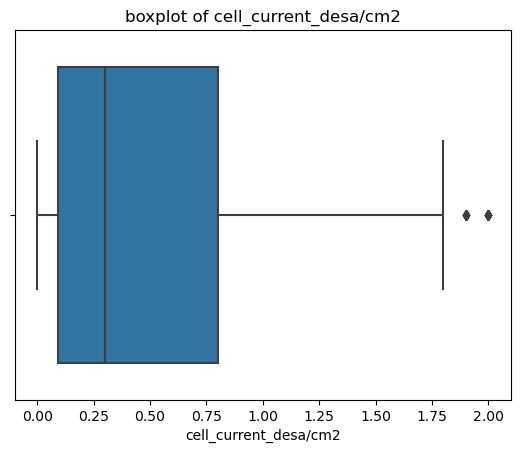

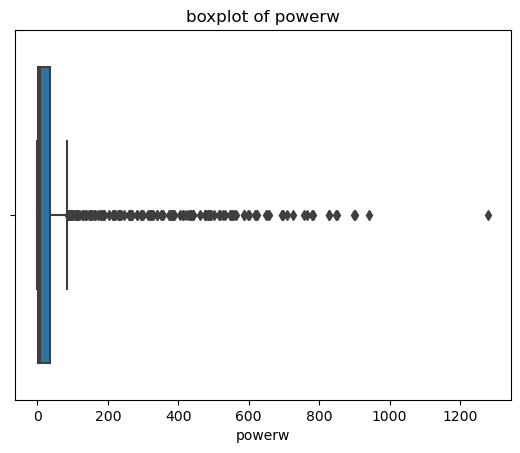

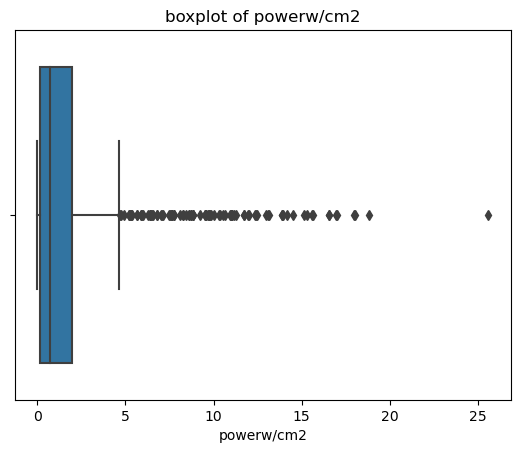

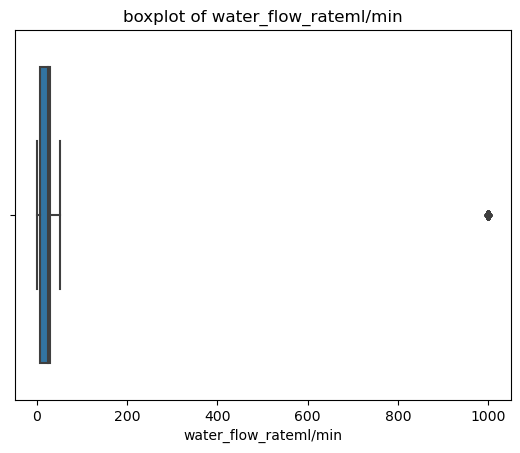

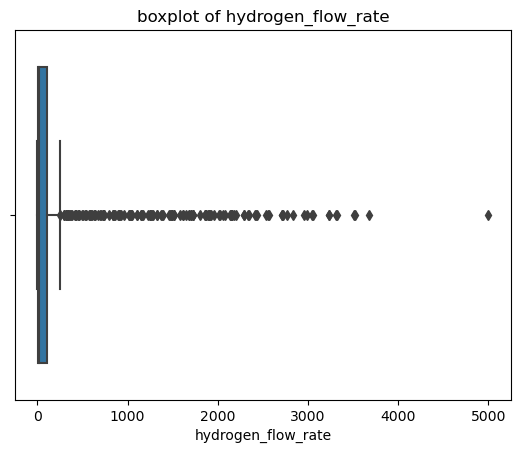

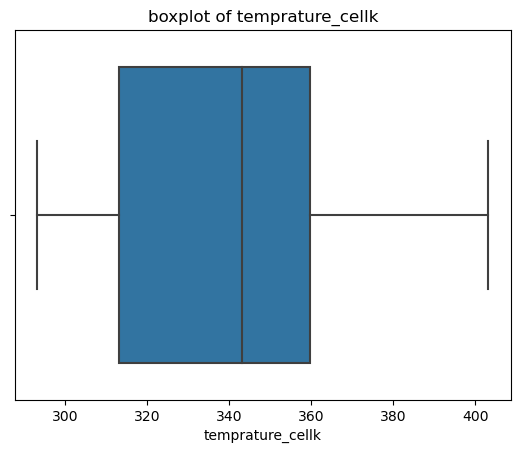

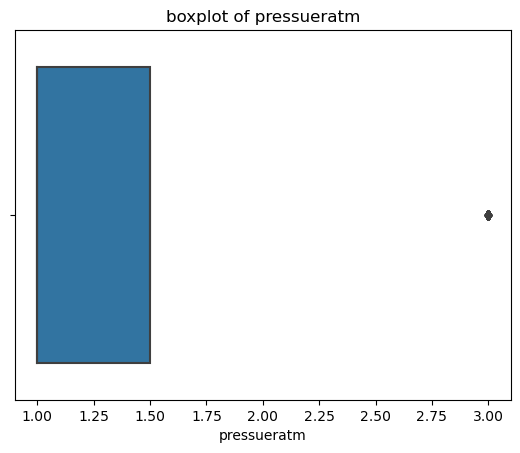

In [14]:
for col in pem.select_dtypes(include=['float64', 'int64']).columns:
    col = str(col)
    sns.boxplot(x=pem[col])
    plt.title('boxplot of ' + col)
    plt.show()

#### Plot correlation matrix

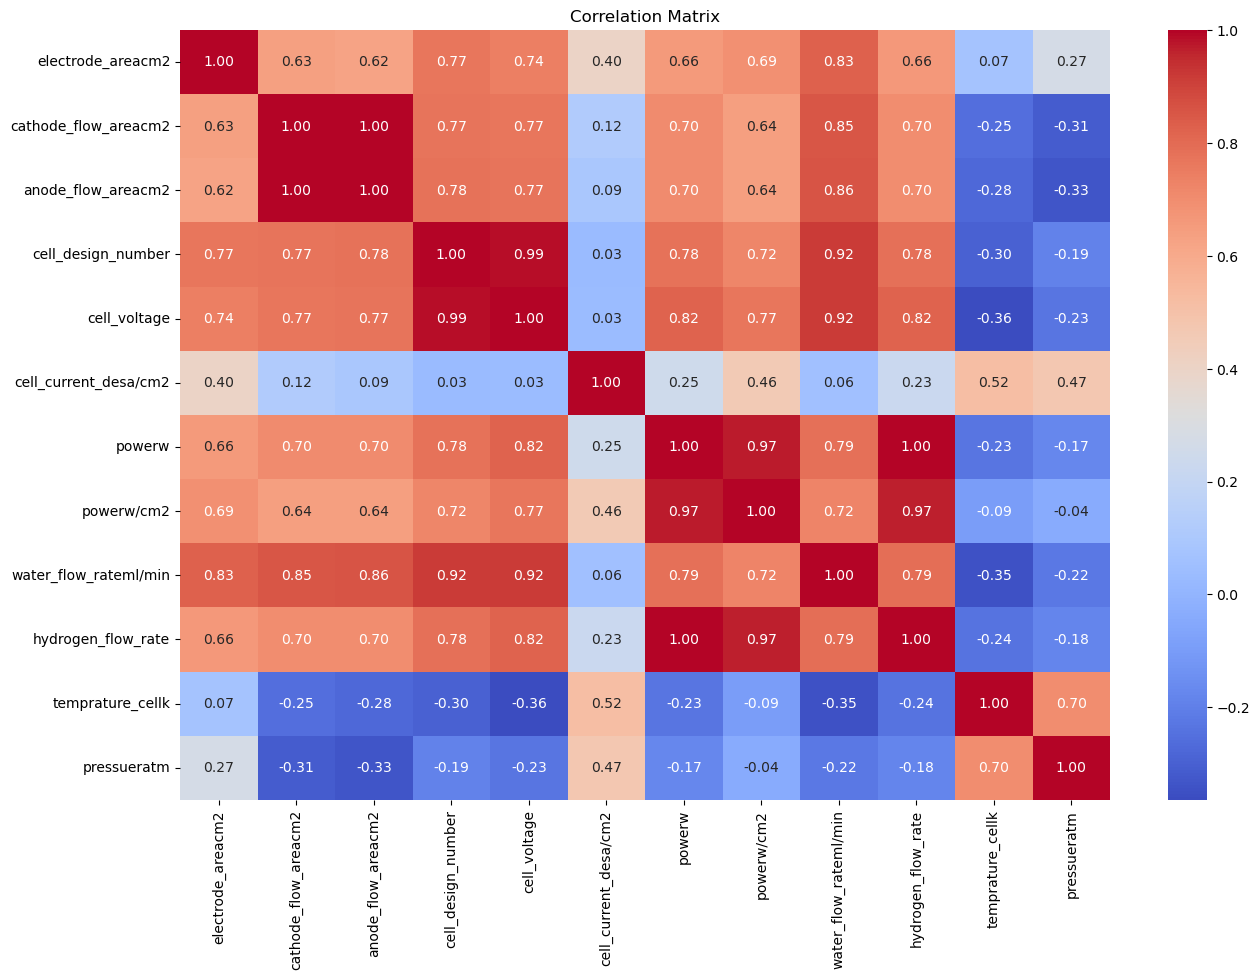

In [15]:
numeric_cols = pem.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_cols.corr()

plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

$Power = current\times voltage$ \
Power has very strong correlation with hydrogen flow rate \
Current per square centimeter has 0.46, 0.25 correlation with power per square centimeter $W/cm^2$, power $(W)$ \
Cell_voltage has 0.82, 0.77 correlation with power per square centimeter $W/cm^2$, power $(W)$ 

As power = current * voltage, it may be beneficial to remove power completely as we risk adding contributions from current and voltage twice, may result in inaccurate ML predicitons.

### To avoid multicollinearity, drop following features:
- Water flow rate
- anode flow area = cathode flow area, so one of these can be dropped.

Upon scaling, what are the most influenetial parameters, can use random forest to work this out

In [16]:
pem.drop('water_flow_rateml/min', inplace=True, axis=1)
pem.drop('cathode_flow_areacm2', inplace=True, axis=1)
pem.head()

,electrolysis_type,anode_type,cathode_type,anode_gde,cathode_gde,electrode_areacm2,anode_flow_areacm2,membrane_type,cathode_catalyst,anode_catalyst,...,cell_voltage,cell_current_desa/cm2,powerw,powerw/cm2,hydrogen_flow_rate,temprature_cellk,pressueratm,electrode_shape,flow_type_a_number,flow_type_c_number
0,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,2.7,0.006964,0.110002,0.018804,0.100,293.15,1.0,rectangular,1,1
1,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.0,0.014786,0.259501,0.044359,0.675,293.15,1.0,rectangular,1,1
2,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.3,0.026414,0.509915,0.087165,1.100,293.15,1.0,rectangular,1,1
3,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.6,0.043238,0.910592,0.155657,1.900,293.15,1.0,rectangular,1,1
4,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.9,0.064428,1.469932,0.251270,3.000,293.15,1.0,rectangular,1,1


In [17]:
# X = pem.drop(['hydrogen_flow_rate','electrolysis_type', 'powerw', 'powerw/cm2'] , axis=1)
# # apply dummy coding for the categorical variables
# X = pd.get_dummies(X, columns=X.select_dtypes(include=['category']).columns)
# X.head()

# # seperate target variable
# Y = pem['hydrogen_flow_rate']

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)
# rf = RandomForestRegressor()

# #fit the model
# rf.fit(X_scaled, Y)
# #use rf to find most important features
# feature_importance = rf.feature_importances_

In [18]:
# #plot relative importance of the features
# indices = np.argsort(feature_importance)[::-1]

# # To plot the top N most important features
# N = 25
# plt.figure(figsize=(10, 6))
# plt.title("Top N Feature Importances")
# plt.bar(range(N), feature_importance[indices[:N]], align="center")
# plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
# plt.xlim([-1, N])
# plt.show()

From the histograms, we can see that there is a large amount of right skewed data, to combat this we can use a logarithmic transformation. \
This will be performed on the following features:\
- Cell_voltage
- Cell_current_desa/cm2
- Water_flow_rateml/min
- Electrode_area
- cathode_flow_arecm2
- andoe_flow_areacm2
- water_flow_rateml/min
- pressureatm

In [19]:
right_skewed_columns = ['cell_voltage', 'cell_current_desa/cm2', 'electrode_areacm2', 'anode_flow_areacm2', 'pressueratm']
for col in right_skewed_columns:
    # add 1 to all, to avoid log(0) error
    pem[col + '_log'] = np.log(pem[col] + 1)
    
# drop the original columns from the dataframe, so the log columns are the only ones that remain
pem.drop(right_skewed_columns, axis=1, inplace=True)



In [20]:
log_columns = []
for i in right_skewed_columns:
    log_columns.append(i + '_log')

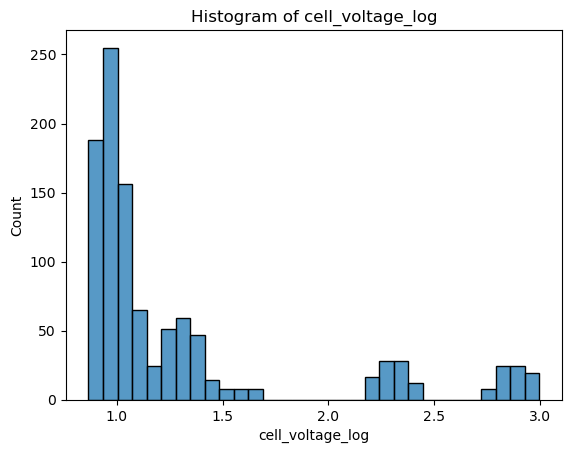

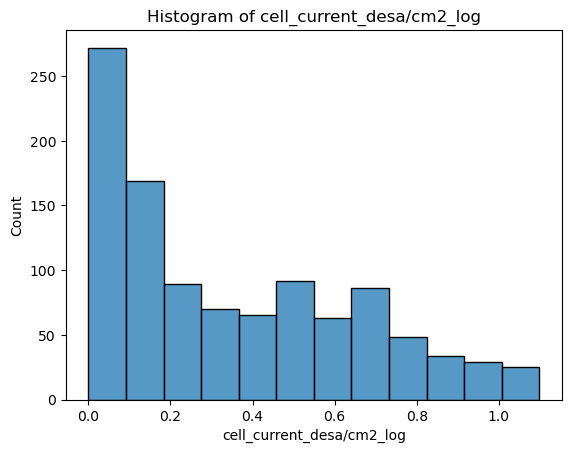

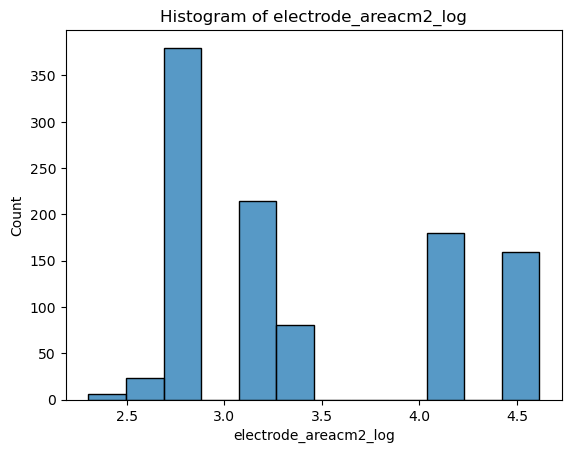

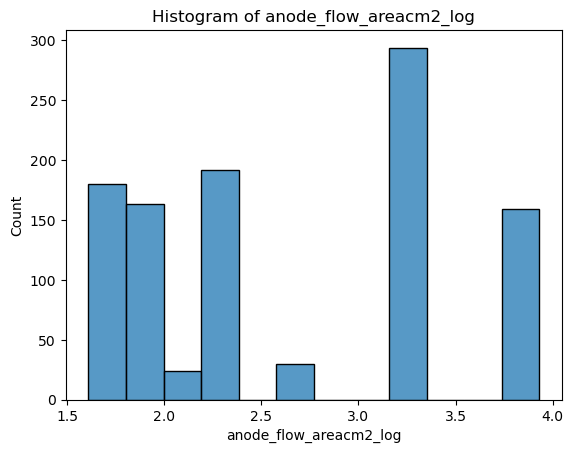

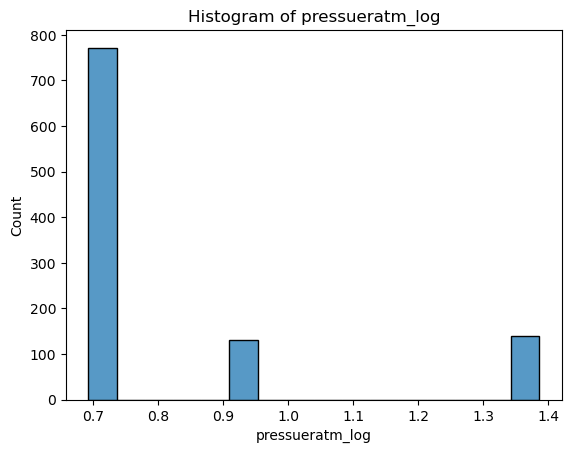

In [21]:
#view histograms and measure skewness
for col in log_columns:
    col = str(col)
    sns.histplot(pem[col])
    plt.title('Histogram of ' + col)
    plt.show()

In [22]:
# remove power and powerw/cm2 from the pem dataframe
pem.drop(['powerw', 'powerw/cm2', 'electrolysis_type'], axis=1, inplace=True)
pem


,anode_type,cathode_type,anode_gde,cathode_gde,membrane_type,cathode_catalyst,anode_catalyst,catholyte,anolyte,cell_design_number,hydrogen_flow_rate,temprature_cellk,electrode_shape,flow_type_a_number,flow_type_c_number,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log
0,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,0.100000,293.15,rectangular,1,1,1.308333,0.006940,2.302585,1.924249,0.693147
1,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,0.675000,293.15,rectangular,1,1,1.386294,0.014678,2.302585,1.924249,0.693147
2,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,1.100000,293.15,rectangular,1,1,1.458615,0.026071,2.302585,1.924249,0.693147
3,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,1.900000,293.15,rectangular,1,1,1.526056,0.042329,2.302585,1.924249,0.693147
4,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,3.000000,293.15,rectangular,1,1,1.589235,0.062438,2.302585,1.924249,0.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1057,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,2718.750000,333.15,round,29,29,2.912351,0.587787,4.615121,3.931826,0.693147
1058,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,2990.625000,333.15,round,29,29,2.923162,0.625938,4.615121,3.931826,0.693147
1059,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,3233.203125,333.15,round,29,29,2.933857,0.657520,4.615121,3.931826,0.693147
1060,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,3515.625000,333.15,round,29,29,2.944439,0.693147,4.615121,3.931826,0.693147


In [23]:
# remove all the categorical variables from the datafram
for col in pem.columns:
    if pem[col].dtypes in ['category']:
        col = str(col)
        pem.drop([col], axis=1, inplace=True)
        

In [24]:
# for log scales :
for col in pem.columns:
    if pem[col].dtypes in ['int64', 'float64']:
        min_value = pem[col].min()
        max_value = pem[col].max()
        print(f"Min, max for {col}:\n min = {min_value}:\n max = {max_value}")

Min, max for cell_design_number:
 min = 1:
 max = 10
Min, max for hydrogen_flow_rate:
 min = 0.0:
 max = 5000.0
Min, max for temprature_cellk:
 min = 293.15:
 max = 403.15
Min, max for cell_voltage_log:
 min = 0.8671004876833833:
 max = 2.995732273553991
Min, max for cell_current_desa/cm2_log:
 min = 0.0002408010051107634:
 max = 1.0986122886681098
Min, max for electrode_areacm2_log:
 min = 2.302585092994046:
 max = 4.61512051684126
Min, max for anode_flow_areacm2_log:
 min = 1.6094379124341003:
 max = 3.9318256327243257
Min, max for pressueratm_log:
 min = 0.6931471805599453:
 max = 1.3862943611198906


In [25]:
pem.head()

,cell_design_number,hydrogen_flow_rate,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log
0,1,0.100,293.15,1.308333,0.006940,2.302585,1.924249,0.693147
1,1,0.675,293.15,1.386294,0.014678,2.302585,1.924249,0.693147
2,1,1.100,293.15,1.458615,0.026071,2.302585,1.924249,0.693147
3,1,1.900,293.15,1.526056,0.042329,2.302585,1.924249,0.693147
4,1,3.000,293.15,1.589235,0.062438,2.302585,1.924249,0.693147


In [26]:
X = pem.drop(['hydrogen_flow_rate'] , axis=1) # Assign hydrogen flow rate as target variable


#scale the features
scaler = StandardScaler()
# scaler = joblib.load('scaler.save')

# seperate target variable
Y = pem['hydrogen_flow_rate']
scaler.fit(X)
joblib.dump(scaler, 'scaler_numeric.joblib')

X_transformed = scaler.transform(X)




# split data into training and test set
X_train_scaled, X_test_scaled, Y_train, Y_test = train_test_split(X_transformed, Y, test_size=0.2, random_state=42)


X_df = pd.DataFrame(X_transformed)

X_df.head()
X_df.describe()

,0,1,2,3,4,5,6
count,1.042000e+03,1.042000e+03,1.042000e+03,1.042000e+03,1.042000e+03,1.042000e+03,1.042000e+03
mean,-5.455223e-17,-8.455595e-16,8.182834e-17,-5.455223e-17,-6.000745e-16,-2.727611e-16,-8.182834e-17
std,1.000480e+00,1.000480e+00,1.000480e+00,1.000480e+00,1.000480e+00,1.000480e+00,1.000480e+00
min,-3.903365e-01,-1.415823e+00,-7.511451e-01,-1.170060e+00,-1.675374e+00,-1.300265e+00,-5.105887e-01
25%,-3.903365e-01,-7.948130e-01,-5.973268e-01,-8.830065e-01,-9.024080e-01,-8.572587e-01,-5.105887e-01
50%,-3.903365e-01,1.367028e-01,-4.683929e-01,-2.910224e-01,-2.834805e-01,-4.417513e-01,-5.105887e-01
75%,-3.903365e-01,6.521415e-01,1.651555e-02,8.002900e-01,1.051281e+00,7.417193e-01,4.312638e-01
max,3.230411e+00,1.999734e+00,2.952271e+00,2.513357e+00,1.693297e+00,1.576182e+00,2.415072e+00


In [27]:
def performance_metrics(Y_test, y_pred):
    """Returns the performance metrics of a ml model"""
    mae = mean_absolute_error(Y_test, y_pred)
    mse = mean_squared_error(Y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, y_pred)
    print('R2 score:', r2)
    print('MSE:',  mse)
    print('RMSE', rmse)
    print('MAE', mae)

In [28]:
# instantiate random forest
rf = RandomForestRegressor()

#fit random forest model
rf.fit(X_train_scaled, Y_train)
y_pred_rf = rf.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_rf)


#use rf to find most important features
feature_importance_rf = rf.feature_importances_

R2 score: 0.9981956344179063
MSE: 761.0696340506435
RMSE 27.587490535578684
MAE 8.302039536670533


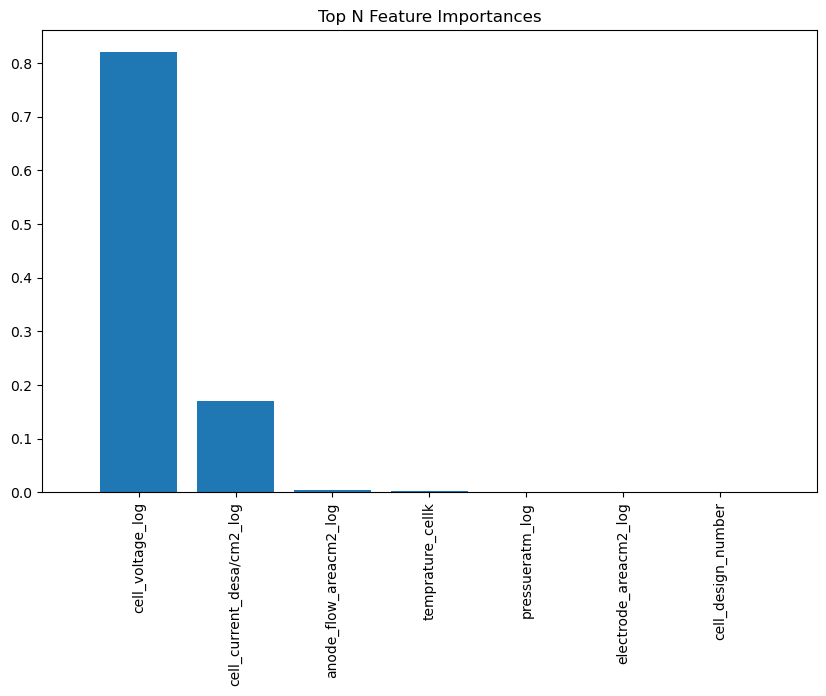

In [29]:
#plot relative importance of the features
indices = np.argsort(feature_importance_rf)[::-1]

# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_rf[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

#### cell_voltage has feature importance of 0.81, which is quite high. To validate this, going to use XGboost to get feature importance as well

In [30]:
# instantiate xgb and fit model
xgb_model = xgb.XGBRegressor()
xgb_model.fit(X_train_scaled, Y_train)

#predicted y values for xgb:
y_pred_xgb = xgb_model.predict(Y_test)
performance_metrics(Y_test, y_pred_xgb)



R2 score: -0.120923071339474
MSE: 472798.04057964624
RMSE 687.6031126890324
MAE 241.65716428785709


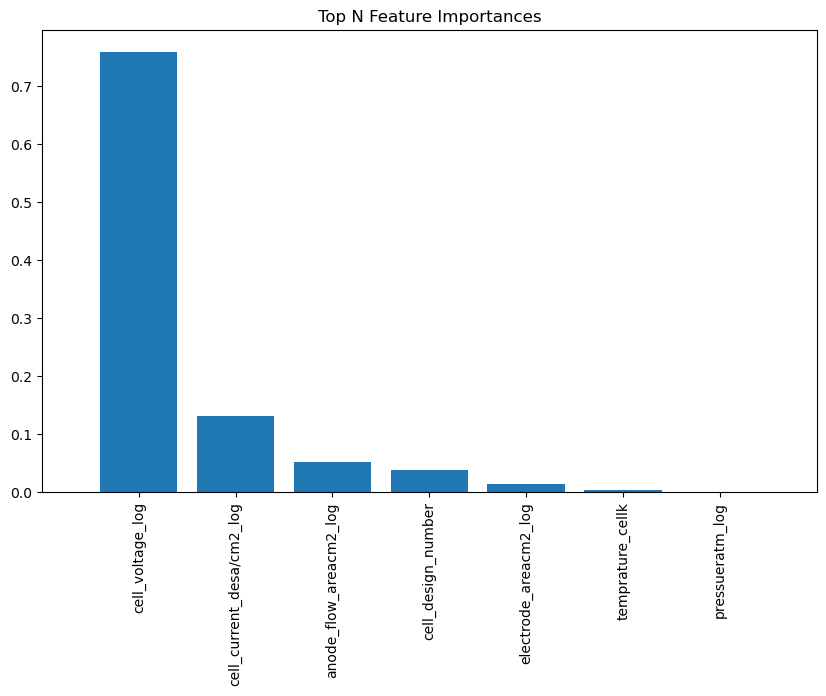

In [31]:
feature_importances_xgb = xgb_model.feature_importances_

#plot relative importance of the features
indices = np.argsort(feature_importances_xgb)[::-1]

# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importances_xgb[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

#### XGB not valid as r2 score is so low, which means model is not accurately predicting
#### so save pem_modified dataset to a csv file

In [32]:

# Instantiate models
linear_model = LinearRegression()
rf_model = RandomForestRegressor()
knn_model = KNeighborsRegressor()
dt_model = DecisionTreeRegressor()
svm_model = SVR()

# Train models
linear_model.fit(X_train_scaled, Y_train)
rf_model.fit(X_train_scaled, Y_train)
knn_model.fit(X_train_scaled, Y_train)
dt_model.fit(X_train_scaled, Y_train)
svm_model.fit(X_train_scaled, Y_train)

SVR()

In [33]:
models = [linear_model, rf_model, knn_model, dt_model, svm_model]
model_names = ['Linear Regression', 'Random Forest', 'KNN', 'Decision Tree', 'SVM']

# evaluate errors
for model, name in zip(models, model_names):
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(Y_test, y_pred)
    mse = mean_squared_error(Y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, y_pred)
    print(f"{name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R²: {r2}")

Linear Regression - MAE: 200.03899262973897, MSE: 124797.81386761255, RMSE: 353.26734050519383, R²: 0.7041257856199363
Random Forest - MAE: 7.559146545229484, MSE: 444.4700752165099, RMSE: 21.08245894615972, R²: 0.9989462376764097
KNN - MAE: 15.864119778080392, MSE: 3360.4246159119675, RMSE: 57.96916952925898, R²: 0.9920330095343568
Decision Tree - MAE: 13.822681237320573, MSE: 1844.1148570452017, RMSE: 42.94315844282069, R²: 0.9956279199318855
SVM - MAE: 210.1215342503816, MSE: 421913.0113056025, RMSE: 649.5483132959414, R²: -0.00028339349915995626


#### Random forest and decision tree should be explored further. Tune hyperparameters using randomized search:

In [34]:
# # Define the RandomForestRegressor model
# rf_model1 = RandomForestRegressor()
# # Define the parameter grid
# param_grid = {
#     'n_estimators': [100, 200, 300],
#     'max_features': ['auto', 'sqrt', 'log2', randint(100,500)],
#     'max_depth': [10, 20, 30, None],
#     'min_samples_split': [2, 5, 10],
#     'min_samples_leaf': [1, 2, 4],
# }

# # Instantiate the regressor
# rf = RandomForestRegressor()

# # Instantiate the grid search model
# grid_search = GridSearchCV(estimator=rf_model1, param_grid=param_grid, 
#                            cv=3, n_jobs=-1, verbose=2)

# # Fit the grid search to the data
# grid_search.fit(X_train_scaled, Y_train)

# # Print the best parameters and the best score
# print("Best parameters:", grid_search.best_params_)
# print("Best score:", grid_search.best_score_)



In [35]:
# best_parameters = random_search.best_params_
# print(best_parameters)

In [36]:
# instantiate rf model with the tuned hyperparameters
rf_model_tuned = RandomForestRegressor(n_estimators=100, max_depth=None, max_features= 'sqrt', min_samples_leaf=1, min_samples_split=2, bootstrap=False)
#fit the model
rf_model_tuned.fit(X_train_scaled, Y_train)

#use rf to find most important features
feature_importance_rf = rf_model_tuned.feature_importances_

joblib.dump(rf_model_tuned, 'rf_tuned.joblib')


['rf_tuned.joblib']

In [37]:
y_pred_rf = rf_model_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_rf)


R2 score: 0.9952310166894348
MSE: 2011.5260560190657
RMSE 44.85003964345032
MAE 11.752730110590777


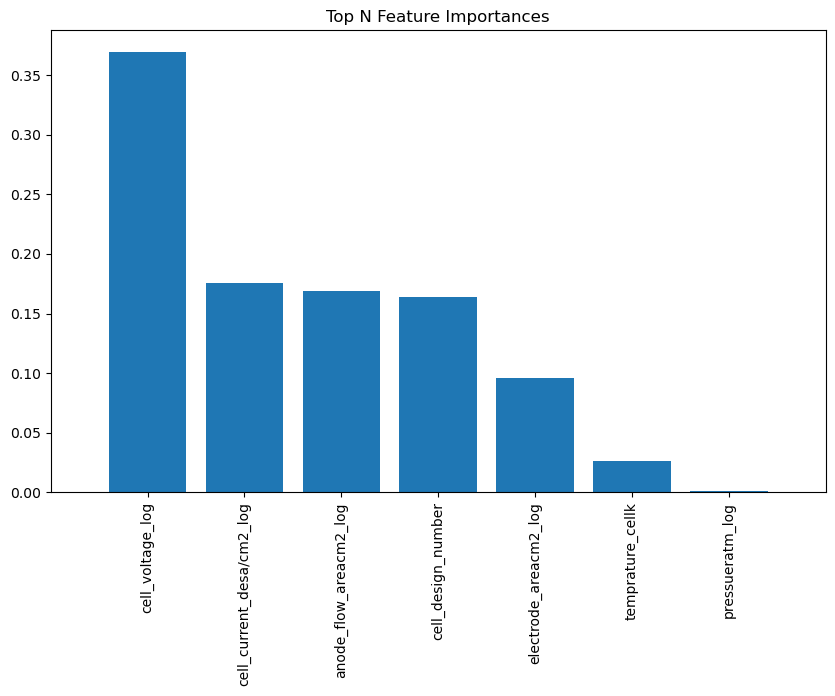

In [38]:
#plot relative importance of the features
indices = np.argsort(feature_importance_rf)[::-1]

# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_rf[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

In [39]:
# # Define the DecisionTreeRegressor model
# dt_model = DecisionTreeRegressor()

# # Define the distribution of hyperparameters for RandomizedSearch
# param_dist = {
#     'max_depth': [None] + list(range(1, 20)),  # Maximum depth of the tree
#     'min_samples_split': randint(2, 20),  # Minimum number of samples required to split a node
#     'min_samples_leaf': randint(1, 20),  # Minimum number of samples required at each leaf node
#     'max_features': ['auto', 'sqrt', 'log2', None]  # Number of features to consider at every split
# }

# # Set up the random search with cross-validation
# random_search_dt = RandomizedSearchCV(dt_model, param_distributions=param_dist, n_iter=100, cv=5, verbose=2, random_state=42, n_jobs=-1)
# random_search_dt.fit(X_train, Y_train)

In [40]:
# #print best params for dt model
# best_params_dt = random_search_dt.best_params_
# print(best_params_dt)

In [41]:
# instantiate dt model with tuned hyperparamaters
dt_model_tuned = DecisionTreeRegressor(max_depth=11, max_features='log2', min_samples_leaf=1, min_samples_split=2)

#fit model
dt_model_tuned.fit(X_train_scaled, Y_train)

#get performance metrics
y_pred_dt = dt_model_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_dt)

# use dt to plot feature importance
feature_importance_dt = dt_model_tuned.feature_importances_


R2 score: 0.9106327729938597
MSE: 37694.51347811834
RMSE 194.1507493627525
MAE 41.79345823095079


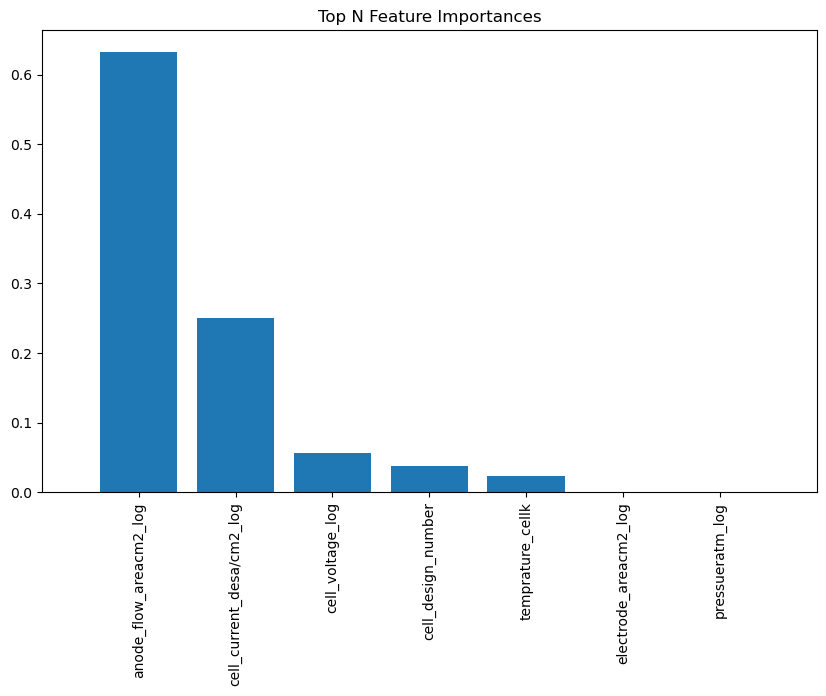

In [42]:
#plot relative importance of the features
indices = np.argsort(feature_importance_dt)[::-1]

# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_dt[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

#### Tune hyperparameters for all machine learning models being considered

# GBM

In [43]:
# # XGB
# xgb_regressor1 = xgb.XGBRegressor()
# params = {
#     'n_estimators': [100, 200, 300, 400, 500],
#     'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
#     'max_depth': [3, 4, 5, 6, 7, 8],
#     'colsample_bytree': [0.3, 0.5, 0.7],
#     'min_child_weight': [1, 3, 5],
#     'subsample': [0.5, 0.7, 0.9]
# }
# random_search = RandomizedSearchCV(xgb_regressor1, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)
# random_search.fit(X_train, Y_train)
# best_model = random_search.best_estimator_
# print("Best hyperparameters:", random_search.best_params_)


In [44]:
#instantiate xgb tuned
xgb_regressor_tuned = xgb.XGBRegressor(subsample=0.9, n_estimators=400, min_child_weight=1, max_depth=3, learning_rate=0.05, colsample_bytree=0.7)
#fit model
xgb_regressor_tuned.fit(X_train_scaled ,Y_train)
#get performance metrics
y_pred_xgb = xgb_regressor_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_xgb)

# use dt to plot feature importance
feature_importance_xgb = xgb_regressor_tuned.feature_importances_


R2 score: 0.9974098419649954
MSE: 1092.5117655741014
RMSE 33.05316574209044
MAE 11.67241255621441


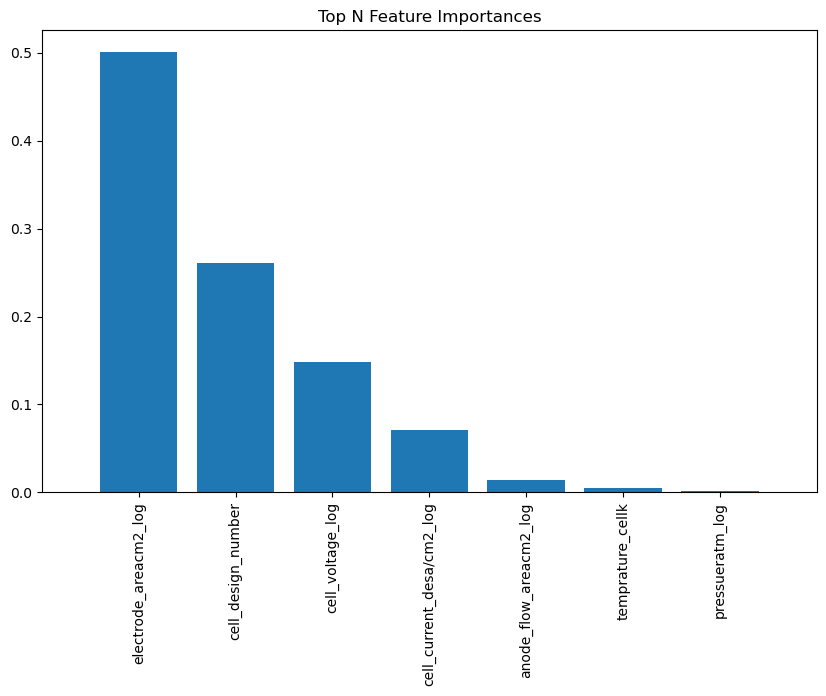

In [45]:
#plot relative importance of the features
indices = np.argsort(feature_importance_xgb)[::-1]

# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_xgb[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

# SVM

In [46]:
# Define your SVR model
# svm_regressor1 = SVR()

# # Set up hyperparameter space
# params = {
#     'C': reciprocal(0.001, 100),  # Regularization parameter
#     'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],  # Type of the kernel
#     'degree': [2, 3, 4, 5],  # Degree of the polynomial kernel
#     'gamma': expon(scale=1.0),  # Kernel coefficient
#     'coef0': [0.0, 0.5, 1.0],  # Independent term in kernel function
#     'shrinking': [True, False],  # Shrinking heuristic
#     'tol': [1e-3, 1e-4, 1e-5],  # Tolerance for stopping criterion
#     'epsilon': [0.01, 0.1, 0.2, 0.5]  # Epsilon in the epsilon-SVR model
# }

# # Configure Randomized Search
# random_search_svm = RandomizedSearchCV(svm_regressor1, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)

# # Fit the Randomized Search Model
# random_search_svm.fit(X_train, Y_train)

# # Best model and hyperparameters
# best_model_svm = random_search_svm.best_estimator_
# print("Best hyperparameters for SVM Regression:", random_search_svm.best_params_)

In [47]:
# svm_regressor_tuned = SVR()
# #fit model
# svm_regressor_tuned.fit(X_train, Y_train)
# #get performance metrics
# y_pred_SVR = svm_regressor_tuned.predict(X_test_scaled)
# performance_metrics(Y_test, y_pred_SVR)

# #feature importance
# feature_importance_SVR = svm_regressor_tuned.feature_importances

In [48]:
# #plot relative importance of the features
# indices = np.argsort(feature_importance_xgb)[::-1]

# # To plot the top N most important features
# N = 25
# plt.figure(figsize=(10, 6))
# plt.title("Top N Feature Importances")
# plt.bar(range(N), feature_importance_xgb[indices[:N]], align="center")
# plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
# plt.xlim([-1, N])
# plt.show()

# KNN regressor

In [49]:
# #instantiate model
# knn_regressor = KNeighborsRegressor()
# # Set up extended hyperparameter space
# params = {
#     'n_neighbors': np.arange(1, 31),  # Number of neighbors to use
#     'weights': ['uniform', 'distance'],  # Weight function used in prediction
#     'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],  # Algorithm used to compute the nearest neighbors
#     'leaf_size': np.arange(1, 50),  # Leaf size passed to BallTree or KDTree
#     'p': [1, 2],  # Power parameter for the Minkowski metric
#     'metric': ['euclidean', 'manhattan', 'chebyshev', 'minkowski']  # Distance metric to use
# }

# # Configure Randomized Search
# random_search_knn = RandomizedSearchCV(knn_regressor, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)

# # Assuming X_train, y_train are defined
# # Fit the Randomized Search Model
# random_search_knn.fit(X_train, Y_train)

# # Best model and hyperparameters
# best_model_knn = random_search_knn.best_estimator_
# print("Best hyperparameters for KNN Regression:", random_search_knn.best_params_)


In [50]:
# instantiate knn regressor tuned
knn_regressor_tuned = KNeighborsRegressor(weights='distance', p=1, n_neighbors=2, metric='manhattan', leaf_size=38, algorithm='brute')
#fit model
knn_regressor_tuned.fit(X_train_scaled, Y_train)
#get performance metrics
y_pred_knn = knn_regressor_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_knn)



R2 score: 0.9953669894814894
MSE: 1954.1736191754635
RMSE 44.206036003870146
MAE 9.019334328672427


In [51]:
# for KNN can use permutation feature importance to get relative importances
result = permutation_importance(knn_regressor_tuned, X_test_scaled, Y_test, n_repeats=10, random_state=42, n_jobs=-1)

indices= result.importances_mean.argsort()[::-1]



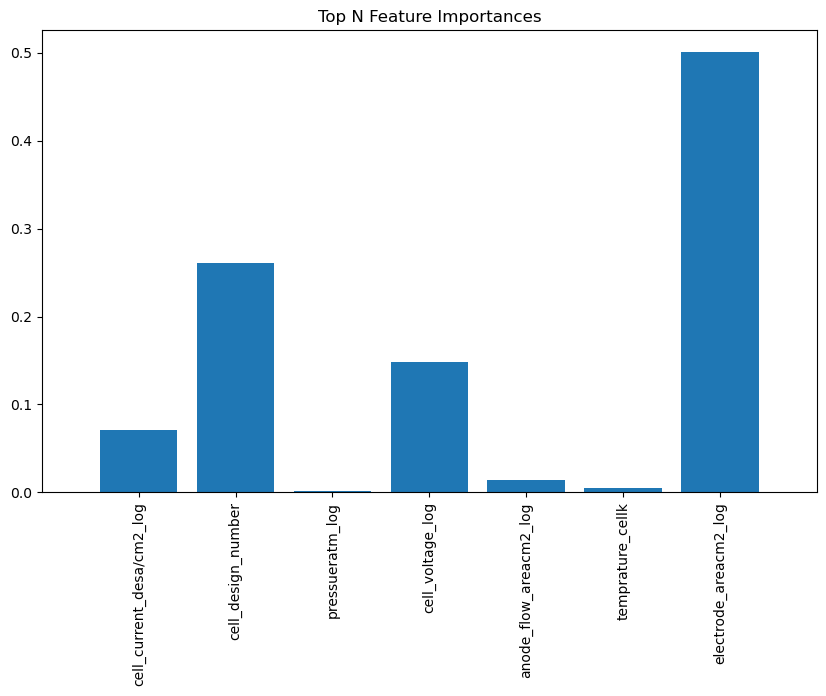

In [52]:
# To plot the top N most important features
N = 7
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_xgb[indices[:N]], align="center")
plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

### Partial Dependence Plots

In [53]:
def format_sigfigs(num, sig_figs):
    return f"{num:.{sig_figs - int(np.floor(np.log10(abs(num)))) - 1}f}"

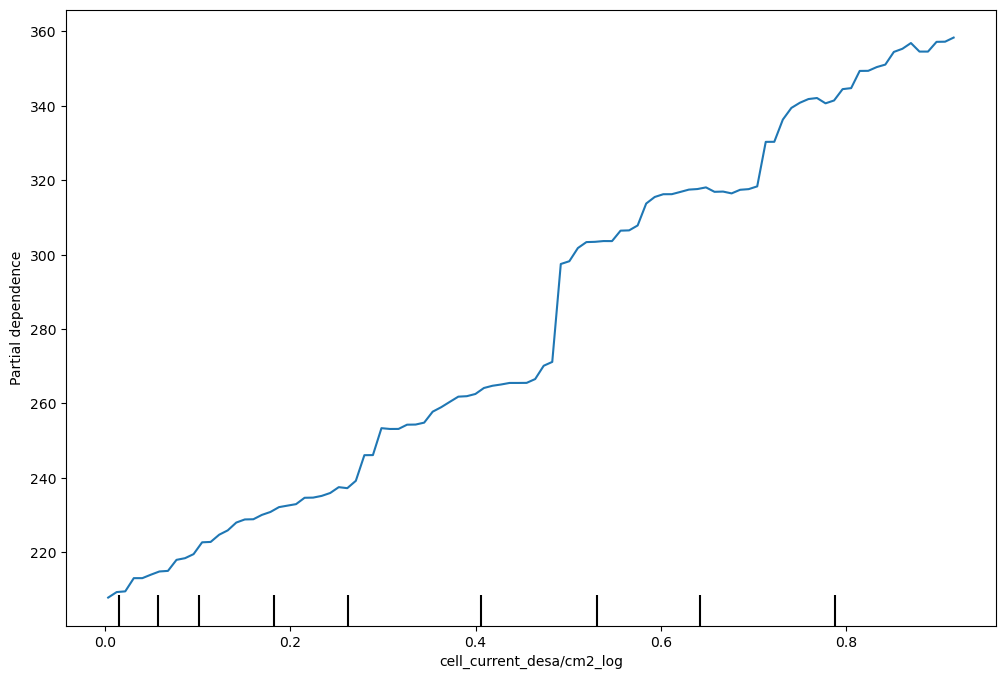

In [54]:
features = ['cell_current_desa/cm2_log']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

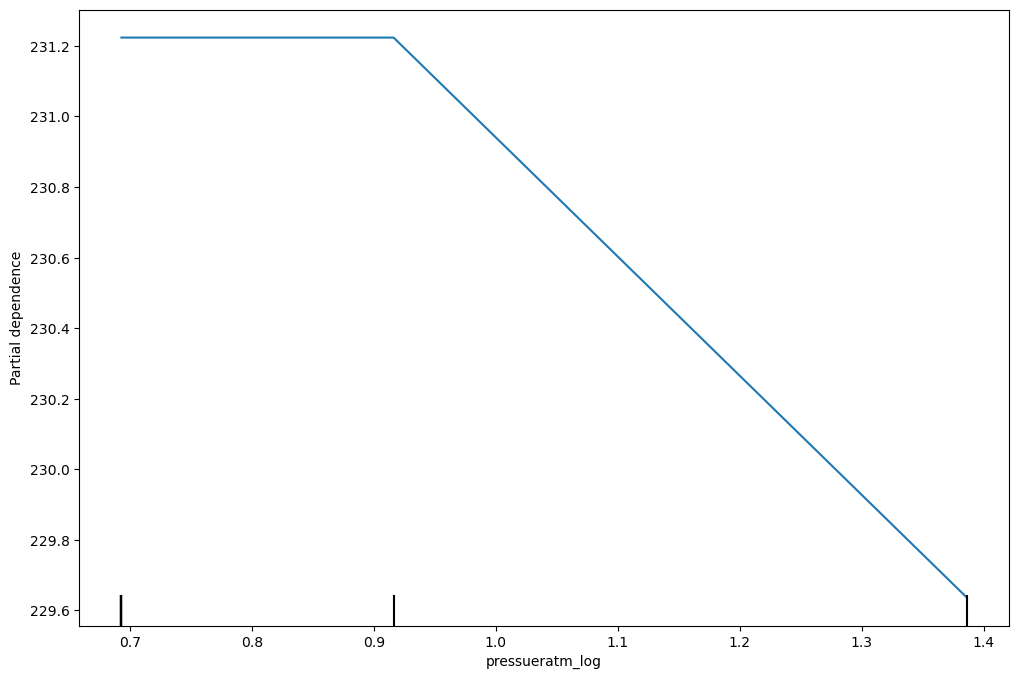

In [55]:
features = ['pressueratm_log']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

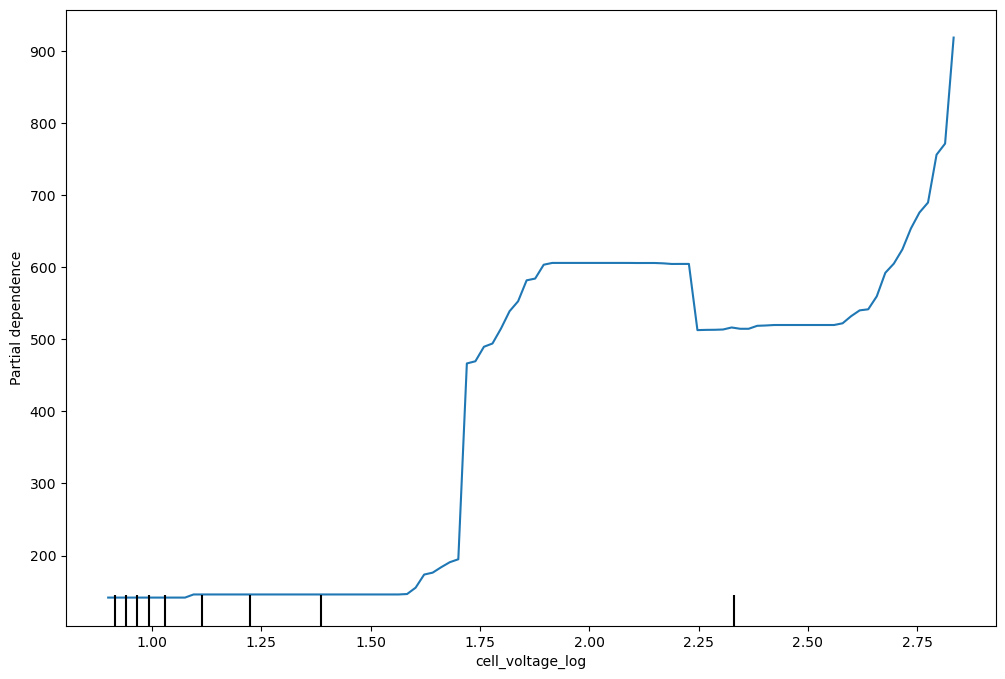

In [56]:
features = ['cell_voltage_log']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

C:\ProgramData\Anaconda3\lib\site-packages\sklearn\inspection\_plot\partial_dependence.py:972: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim([min_val, max_val])


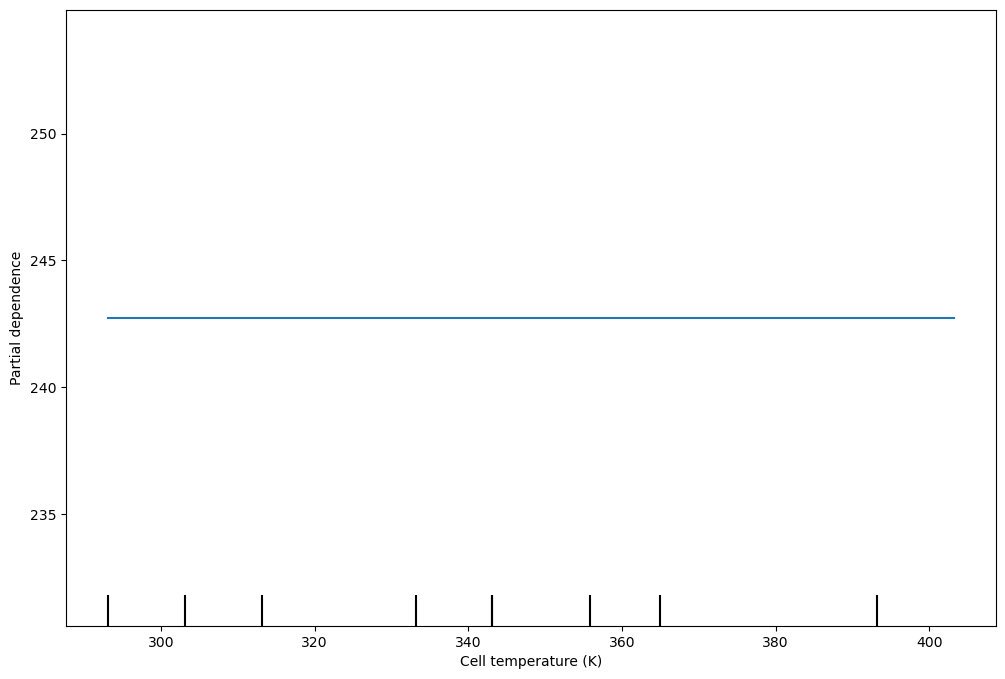

In [57]:
features = ['temprature_cellk']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.xlabel('Cell temperature (K)')
plt.show()

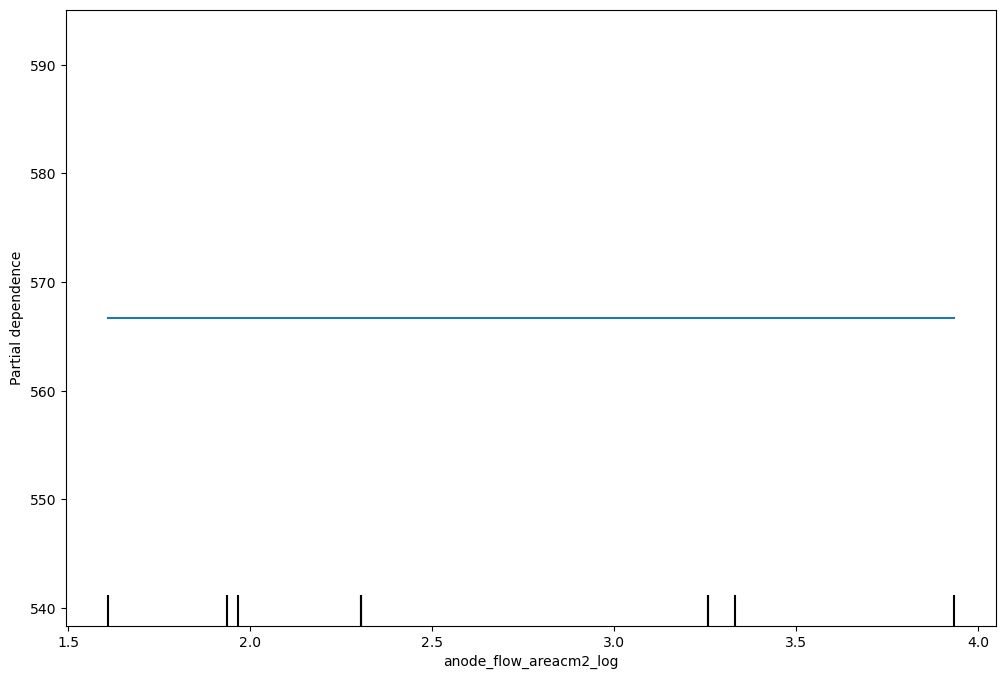

In [58]:
features = ['anode_flow_areacm2_log']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

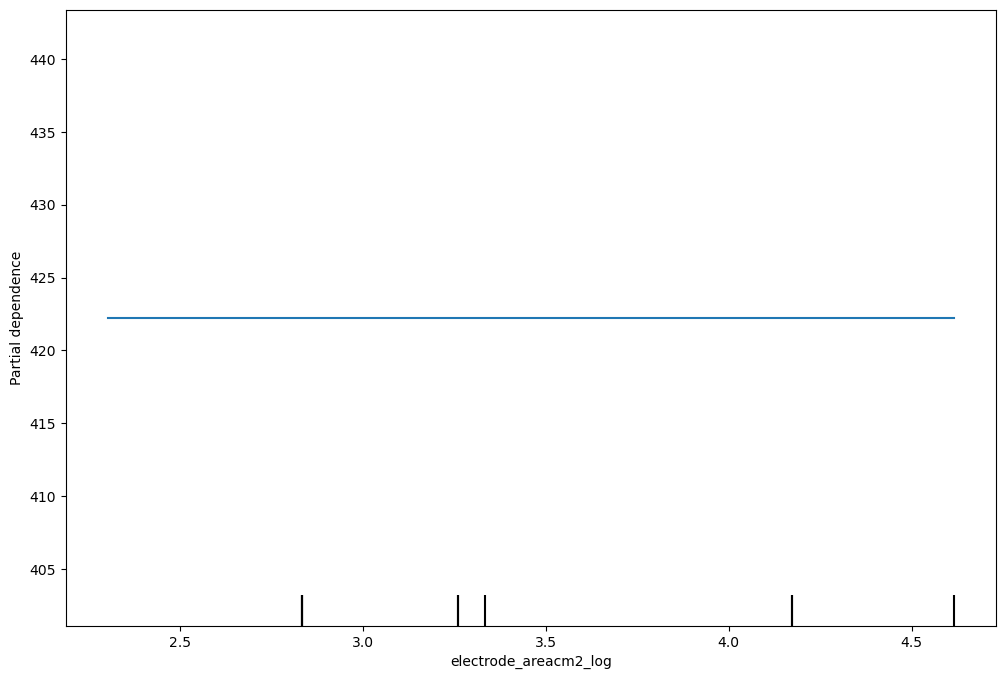

In [59]:
features = ['electrode_areacm2_log']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

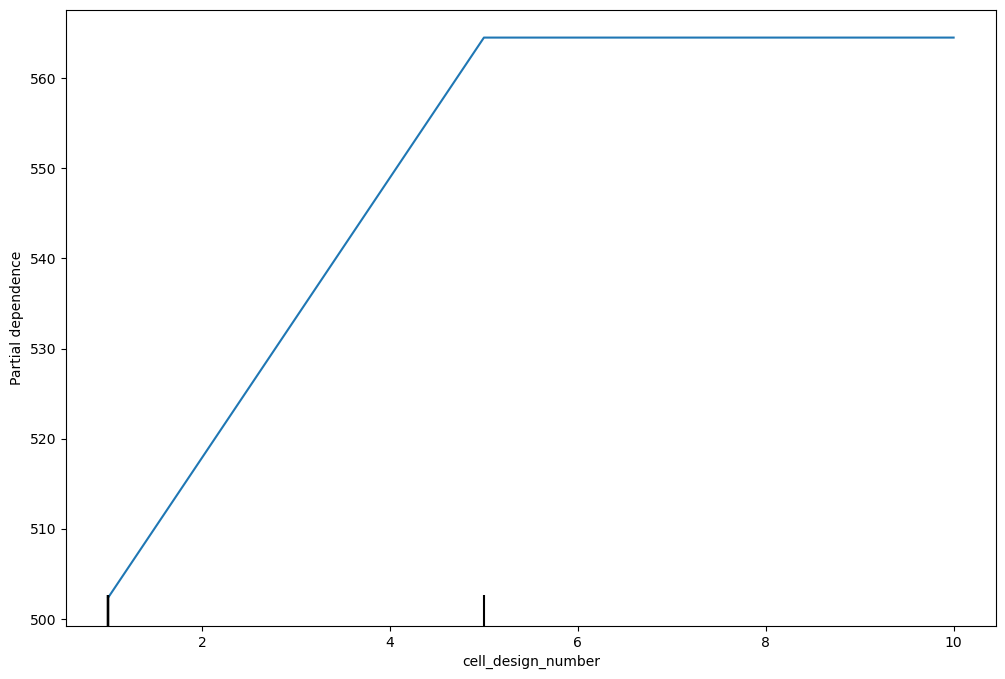

In [60]:
features = ['cell_design_number']
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

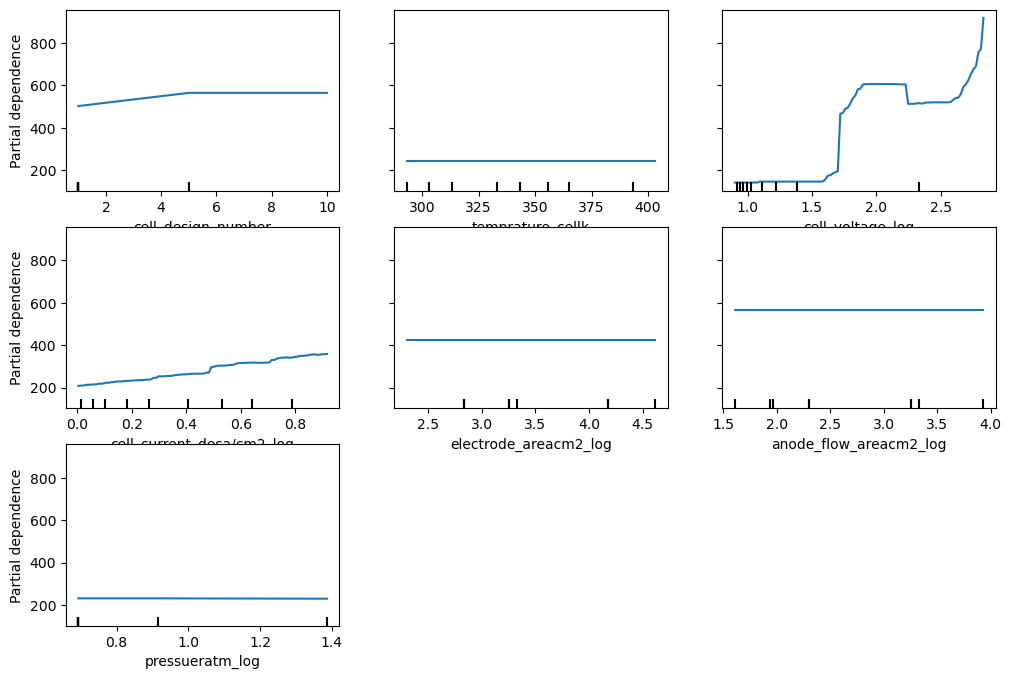

In [61]:
features = [0,1, 2, 3, 4,  5, 6]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X, features, ax=ax)
plt.show()

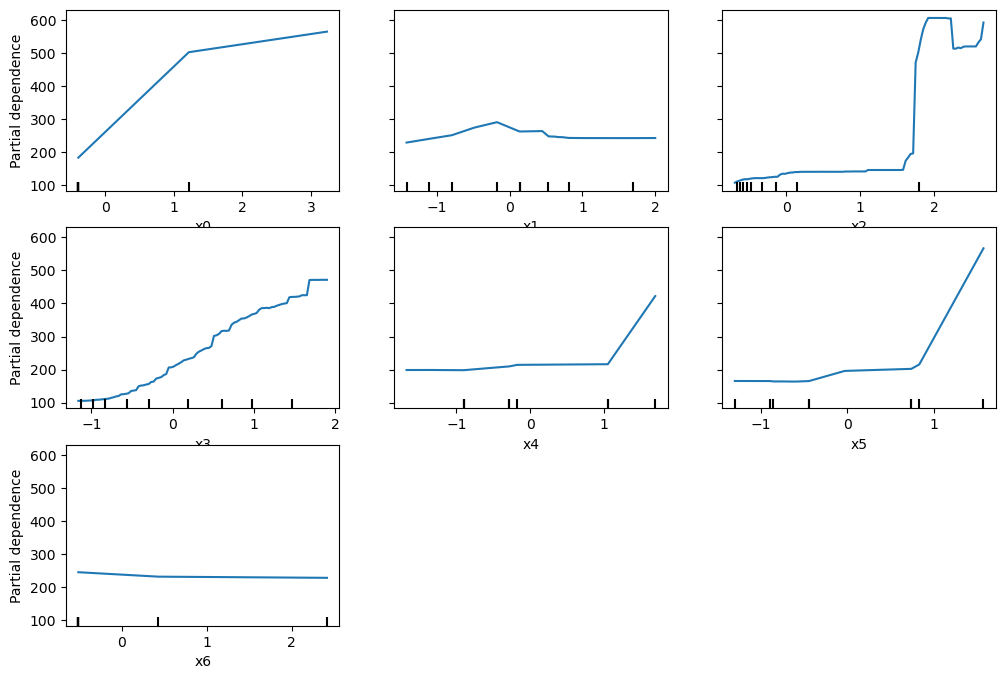

In [62]:
features = [0,1, 2, 3, 4,  5, 6]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)
plt.show()

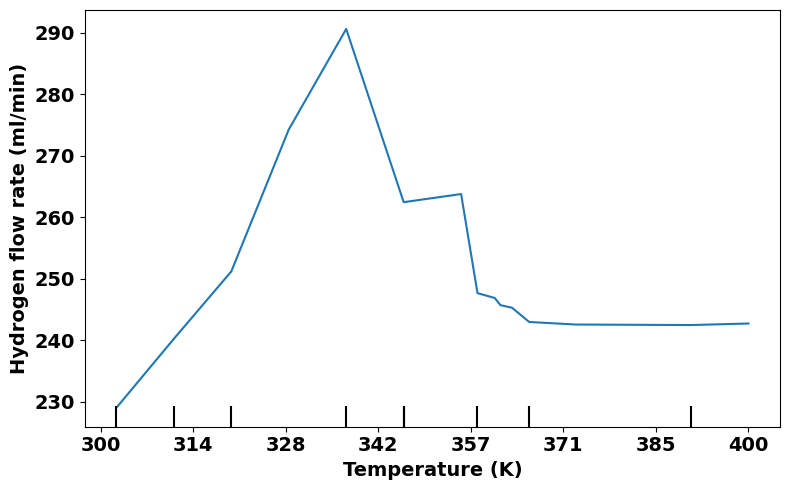

In [66]:
# Temperature

features = [1]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 5))
  # must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


#change labels
original_ticks = np.linspace(-1.5, 2, num=8)
new_labels = np.linspace(300, 400, num=8).astype(int)
# Set the new tick labels
plt.yticks(fontweight='bold', fontsize=14)
plt.xticks(ticks=original_ticks, labels=new_labels, fontweight='bold', fontsize=14)
plt.xlabel('Temperature (K)', fontweight='bold', fontsize=14)
plt.ylabel('Hydrogen flow rate (ml/min)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('temp partial dependence.png', dpi=500)
plt.show()

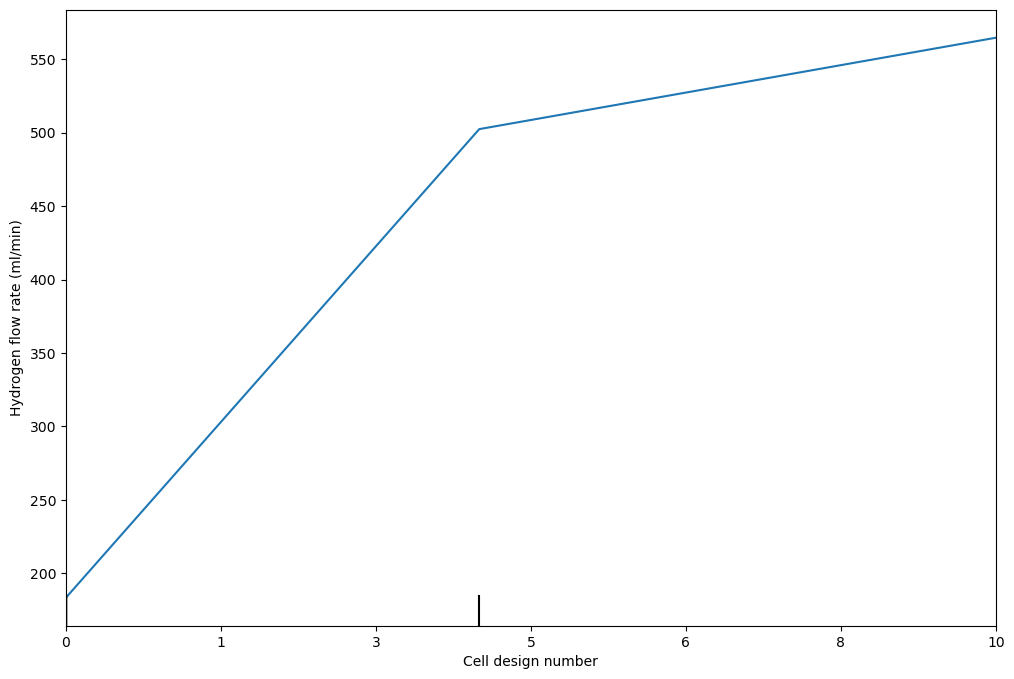

In [67]:
#Cell design number
features = [0]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


#change labels
plt.xlim(-0.3903365, 3.230411)
original_ticks = np.linspace(-0.3903365, 3.230411, num=7)
new_labels = np.linspace(0, 10, num=7).astype(int)
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels)
plt.xlabel('Cell design number')
plt.ylabel('Hydrogen flow rate (ml/min)')
plt.show()

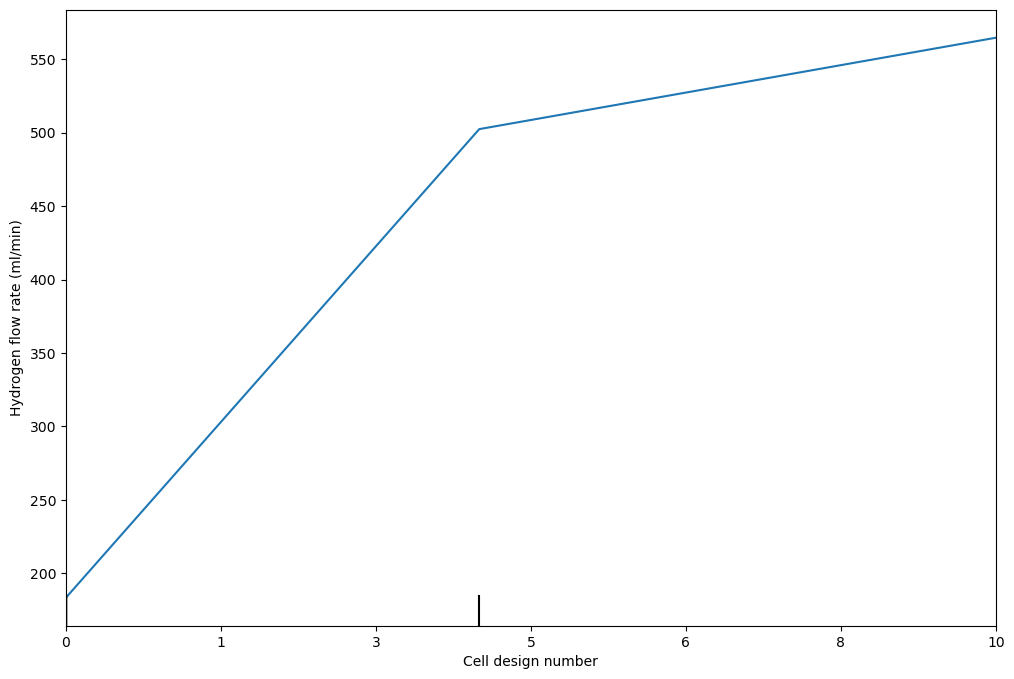

In [68]:
#Cell design number
features = [0]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


#change labels
plt.xlim(-0.3903365, 3.230411)
original_ticks = np.linspace(-0.3903365, 3.230411, num=7)
new_labels = np.linspace(0, 10, num=7).astype(int)
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels)
plt.xlabel('Cell design number')
plt.ylabel('Hydrogen flow rate (ml/min)')
plt.show()

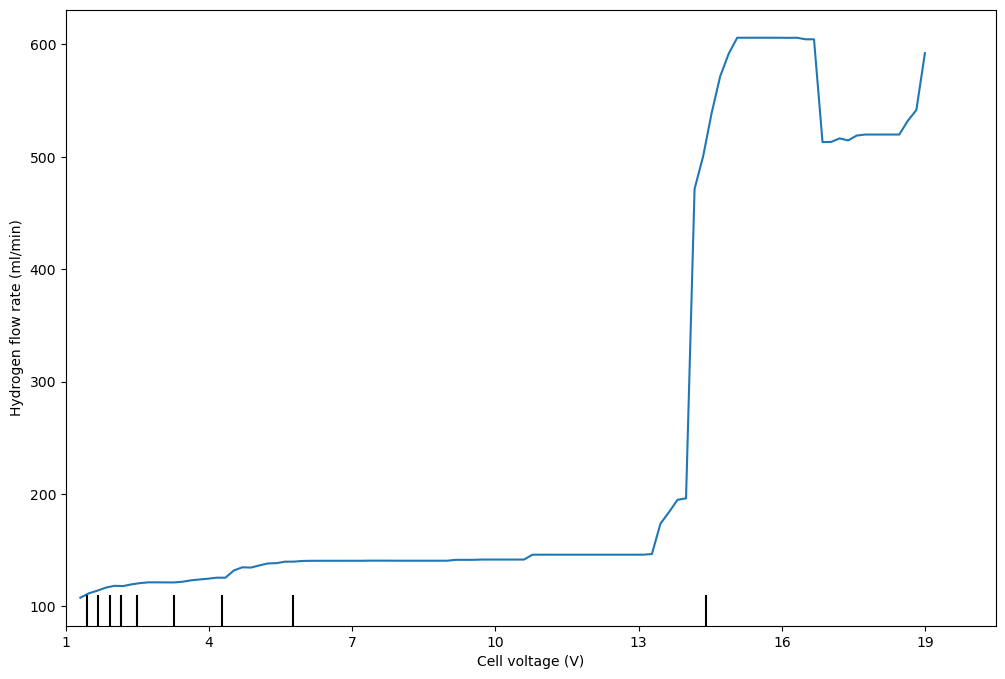

In [69]:
# Cell voltage
features = [2]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


#change labels
plt.xlim(-0.7511451, 2.952271)
original_ticks = np.linspace(-0.7511451, 2.67, num=7)
new_labels = np.linspace(1.380000, 19.000000, num=7).astype(int)
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels)
plt.xlabel('Cell voltage (V)')
plt.ylabel('Hydrogen flow rate (ml/min)')
plt.show()

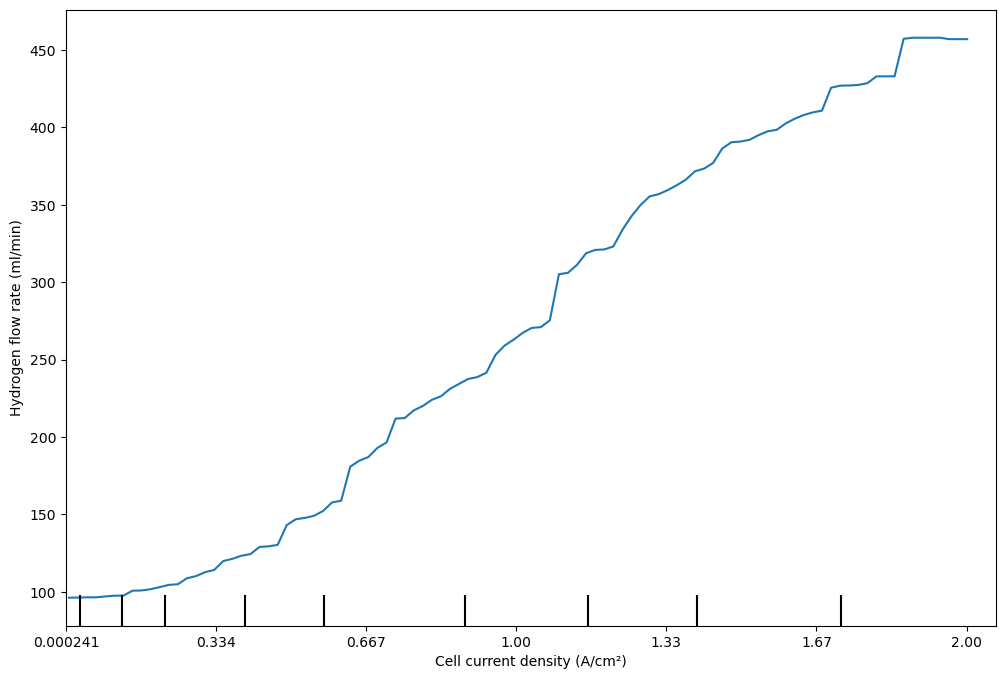

In [185]:
# Cell current density
features = [3]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


#change labels
plt.xlim(-1.17006, 2)
original_ticks = np.linspace(-1.1706, 1.9, num=7)
new_labels = [format_sigfigs(label, 3) for label in np.linspace(0.000241, 2, num=7)]
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels)
plt.xlabel('Cell current density (A/cm\u00B2)')
plt.ylabel('Hydrogen flow rate (ml/min)')
plt.show()

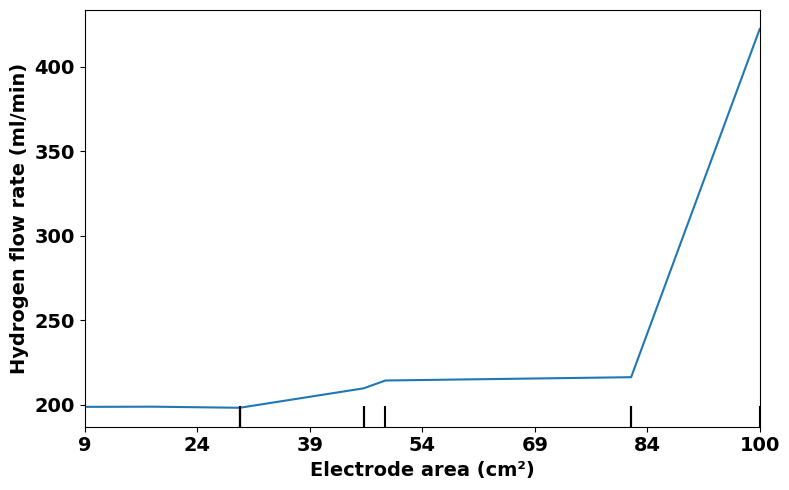

In [72]:
#Electrode area
features = [4]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 5))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


# #change labels
plt.xlim(-1.675374, 1.693297)
original_ticks = np.linspace(-1.67573, 1.693297, num=7)
new_labels = np.linspace(9, 100 , num=7).astype(int)
# Set the new tick labels
plt.yticks(fontweight='bold', fontsize=14)
plt.xticks(ticks=original_ticks, labels=new_labels, fontweight='bold',fontsize=14)
plt.xlabel('Electrode area (cm\u00B2)', fontweight='bold',fontsize=14)
plt.ylabel('Hydrogen flow rate (ml/min)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('electrode area pda.png', dpi=500)
plt.show()

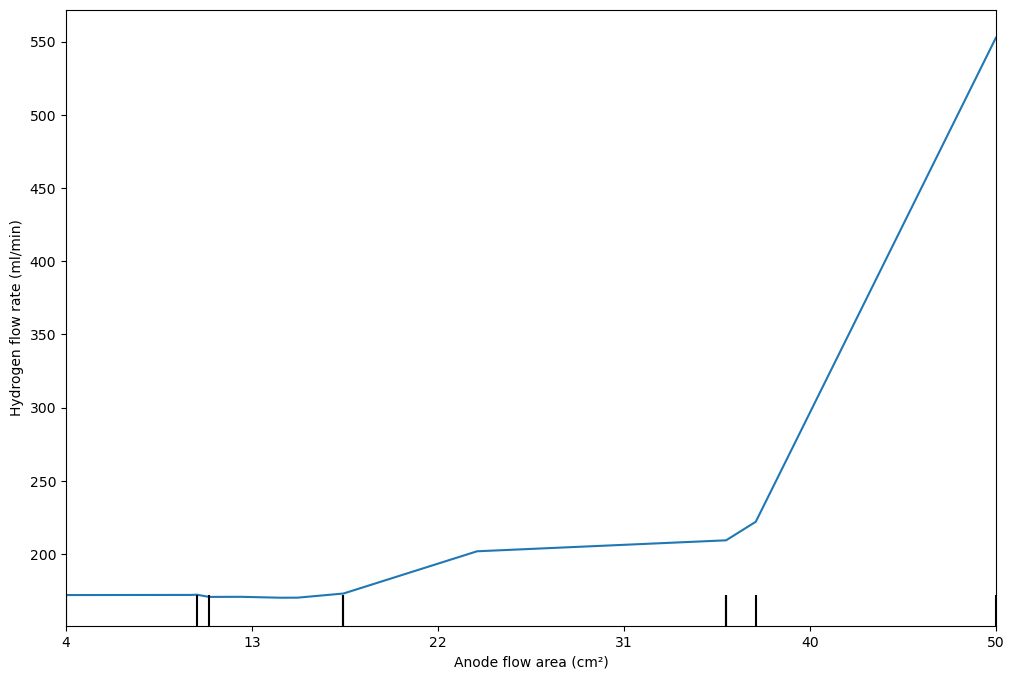

In [176]:
#Anode flow  area
features = [5]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(12, 8))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


# # #change labels
plt.xlim(-1.300265, 1.576182)
original_ticks = np.linspace(-1.300265, 1.576182, num=6)
new_labels = np.linspace(4, 50 , num=6).astype(int)
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels)
plt.xlabel('Anode flow area (cm\u00B2)')
plt.ylabel('Hydrogen flow rate (ml/min)')
plt.show()

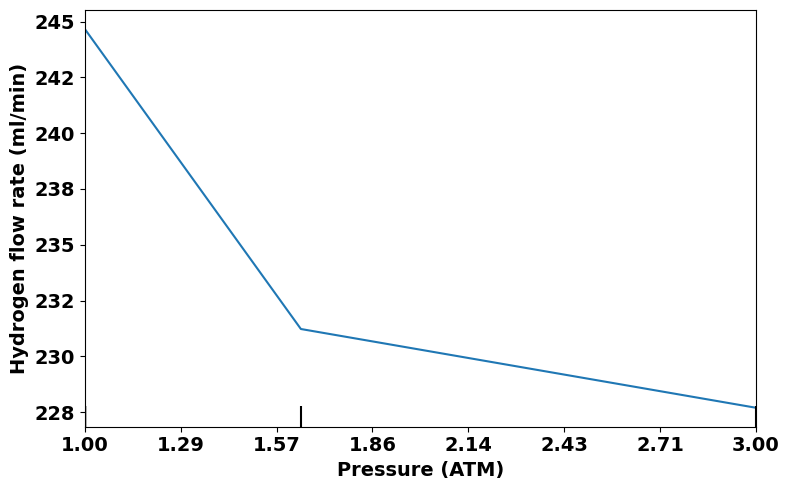

In [86]:
#Pressure
features = [6]

# Create the partial dependence plot
fig, ax = plt.subplots(figsize=(8, 5))
# must match the number of original ticks


display = PartialDependenceDisplay.from_estimator(rf_model_tuned, X_transformed, features, ax=ax)


# # #change labels
plt.xlim(-0.5105887, 2.4150)
original_ticks = np.linspace(-0.5105887, 2.4150, num=8)
original_y_ticks = np.linspace(227.5, 245, num=8)

new_y_ticks = [f'{tick:.3g}' for tick in original_y_ticks]
new_labels = [format_sigfigs(label, 3) for label in np.linspace(1, 3, num=8)]
# Set the new tick labels
plt.xticks(ticks=original_ticks, labels=new_labels, fontweight='bold', fontsize=14)
plt.xlabel('Pressure (ATM)', fontsize=14, fontweight='bold')
plt.ylabel('Hydrogen flow rate (ml/min)', fontsize=14, fontweight='bold')
plt.yticks(ticks=original_y_ticks, labels=new_y_ticks, fontweight='bold',fontsize=14)
plt.tight_layout()
plt.savefig('pressure PDA.png',dpi=500)
plt.show()